# 🚀 Cross-Domain Few-Shot Segmentation (CDFSS): Tái Lập Chuẩn 100% Theo Mã Nguồn Tác Giả (LoEC)
**Bài báo:** *The Devil is in Low-Level Features for Cross-Domain Few-Shot Segmentation* (arXiv:2503.21150)  
**Tác giả:** Yuhan Liu, Yixiong Zou, Yuhua Li, Ruixuan Li (Huazhong University of Science and Technology - HUST)  

---
### 📌 Cấu hình Môi trường & 5 Bộ Dữ liệu cần gắn trong `/kaggle/input/`:
* **Accelerator:** Chọn **GPU T4 x 1** hoặc **P100** (16GB VRAM).
* **Internet:** Bật **ON** (để tự động tải pre-trained weights ResNet-50).
* **5 bộ dữ liệu thật trong mục Input (`+ Add Input`):**
  1. **Miền Nguồn:** `PASCAL VOC 2012 DATASET` (hoặc bản có `SegmentationClassAug`)
  2. **Miền Đích 1 (X-quang):** `Chest Xray Masks and Labels`
  3. **Miền Đích 2 (Da liễu - Có Mask):** Chọn bộ **ISIC 2018 Task 1 Segmentation** (ví dụ: `isic2018-challenge-task1-data-segmentation` hoặc `isic-2018-task-1-2-training-data` — *lưu ý: không dùng bản `ISIC 2018 JPG 256x256 RESIZED` vì bản đó chỉ có ảnh `.jpg`, không có thư mục GroundTruth Mask*)
  4. **Miền Đích 3 (Vệ tinh):** `DeepGlobe Land Cover Classification Dataset` (hoặc `DeepGlobe Road Extraction Dataset`)
  5. **Miền Đích 4 (Đồ vật):** `FSS-1000: A 1000 Class Few-shot Segmentation`


## 1. Khởi Tạo Môi Trường & Seed


In [1]:
import os
import glob
import random
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms.functional as TF

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[*] Thiết bị đang dùng: {device}")
if torch.cuda.is_available():
    print(f"[*] GPU: {torch.cuda.get_device_name(0)}")
    print(f"[*] VRAM khả dụng: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)
print("[✓] Seed đã cố định tại 42.")


[*] Thiết bị đang dùng: cuda
[*] GPU: Tesla T4
[*] VRAM khả dụng: 15.64 GB
[✓] Seed đã cố định tại 42.


## 2. Backbone ResNet-50 (SSP Modified)
Trích xuất `layer0` (stem), `layer1`, `layer2`, `layer3` (với dilation cho layer3 để giữ độ phân giải không gian).


In [2]:
import types

class ResNet50_LoEC(nn.Module):
    def __init__(self, pretrained=True):
        super(ResNet50_LoEC, self).__init__()
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        base = models.resnet50(weights=weights)

        self.conv1 = base.conv1
        self.bn1 = base.bn1
        self.relu = base.relu
        self.maxpool = base.maxpool
        self.layer1 = base.layer1
        self.layer2 = base.layer2
        self.layer3 = base.layer3

        # 1. Dilation cho layer3 theo chuẩn FSS/SSP
        for n, m in self.layer3.named_modules():
            if 'conv2' in n:
                m.dilation = (2, 2)
                m.padding = (2, 2)
                m.stride = (1, 1)
            elif 'downsample.0' in n:
                m.stride = (1, 1)

        # 2. Bỏ ReLU cuối cùng của layer3 (Mục 4.2 bài báo: 'discard the last backbone stage and the last ReLU')
        last_block = self.layer3[-1]
        def _forward_no_last_relu(block_self, x):
            identity = x
            out = block_self.relu(block_self.bn1(block_self.conv1(x)))
            out = block_self.relu(block_self.bn2(block_self.conv2(out)))
            out = block_self.bn3(block_self.conv3(out))
            if block_self.downsample is not None:
                identity = block_self.downsample(x)
            out += identity
            return out  # Không qua ReLU cuối để giữ toàn bộ miền giá trị cho Cosine Similarity
        last_block.forward = types.MethodType(_forward_no_last_relu, last_block)

    def forward(self, x):
        pass


## 3. Kiến Trúc Chuẩn Từ Mã Nguồn Tác Giả (`SSP_MatchingNet` trong `LoEC.py`)
Bao gồm đầy đủ 100% các thuật toán gốc do tác giả viết:
1. **`feat_RCfourier_bias` (LEM):** Grouped Random Convolution + Phân tách Fourier (giữ nguyên pha gốc, thay biên độ nhiễu). Đã bọc `autocast(enabled=False)` trên `float32/complex64` để chạy mượt mà trên cuFFT Kaggle.
2. **`mask_correction` (LCM):** Tính độ tin cậy tiền cảnh, chọn Top-$K$ patch (K=1), tính ma trận khoảng cách Euclidean của màu sắc RGB trên ảnh query `q_ori` và điều chế tỉ lệ điểm số tiền cảnh:
   $$S_{fg} = S_{fg} + S_{fg} \times (\text{Sim} - \beta) \times w$$
3. **`SSP_func` (Self-Support Matching):** Tự động bóc tách prototype tiền cảnh/hậu cảnh nội bộ của ảnh Query và trộn thích nghi với Support Prototype.


In [3]:
class SSP_MatchingNet(nn.Module):
    def __init__(self, pretrained=True, refine=False):
        super(SSP_MatchingNet, self).__init__()
        backbone = ResNet50_LoEC(pretrained=pretrained)
        self.layer0 = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.refine = refine

        # Đóng băng tham số của layer0 và layer1 (theo LoEC.py dòng 27-40 & Bảng 1 bài báo)
        for p in self.layer0.parameters():
            p.requires_grad = False
        for p in self.layer1.parameters():
            p.requires_grad = False

    def train(self, mode=True):
        super(SSP_MatchingNet, self).train(mode)
        # Giữ layer0, layer1 và các tầng BatchNorm ở chế độ eval() theo chuẩn FSS/SSP
        self.layer0.eval()
        self.layer1.eval()
        for m in self.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
        return self

    # -------------------------------------------------------------
    # LEM: Low-level Enhancement Module (LoEC.py dòng 255)
    # -------------------------------------------------------------
    def feat_RCfourier_bias(self, feat, b, h, w, in_channels, out_channels, kernel_size=3):
        random_convolution = nn.Conv2d(
            b * in_channels, b * out_channels, kernel_size, 
            padding=kernel_size // 2, groups=b, bias=True
        ).to(feat.device)
        torch.nn.init.kaiming_normal_(random_convolution.weight, mode="fan_in", nonlinearity="relu")

        feat_reshaped = feat.view(1, b * in_channels, h, w)
        feat_RC = random_convolution(feat_reshaped)
        feat_RC = feat_RC.view(b, out_channels, h, w)

        # Tắt autocast để FFT chạy trên float32 (tránh lỗi cuFFT half-precision trên kích thước không là lũy thừa của 2)
        try:
            autocast_off = torch.amp.autocast(feat.device.type, enabled=False)
        except (AttributeError, TypeError):
            autocast_off = torch.cuda.amp.autocast(enabled=False)

        with autocast_off:
            feat_fp32 = feat.float()
            feat_RC_fp32 = feat_RC.float()

            feat_fft = torch.fft.fft2(feat_fp32, dim=(-2, -1))
            feat_RC_fft = torch.fft.fft2(feat_RC_fp32, dim=(-2, -1))

            amp, phase = torch.abs(feat_fft), torch.angle(feat_fft)
            amp_RC, phase_RC = torch.abs(feat_RC_fft), torch.angle(feat_RC_fft)

            # Recombination: RC amp + ori phase (giữ nguyên cấu trúc ranh giới, biến dạng miền phong cách)
            new_complex = amp_RC * torch.exp(1j * phase)
            new_feat = torch.real(torch.fft.ifft2(new_complex))

        return new_feat.to(dtype=feat.dtype)

    # -------------------------------------------------------------
    # LCM: Low-level Calibration Module (LoEC.py dòng 126)
    # -------------------------------------------------------------
    def mask_correction(self, out, q_ori, patch_size=16, K=1):
        if q_ori.dim() == 4 and q_ori.shape[1] == 3:
            q_ori = q_ori.permute(0, 2, 3, 1)

        b, h, w = out.shape[0], out.shape[2], out.shape[3]
        out_confidence = out[:, 1, :, :] - out[:, 0, :, :]  # fg - bg

        num_patches_x = h // patch_size
        num_patches_y = w // patch_size
        patch_confidence = out_confidence.view(b, num_patches_x, patch_size, num_patches_y, patch_size).permute(0, 1, 3, 2, 4)
        patch_confidence_means = patch_confidence.mean(dim=(3, 4))

        total_patches = num_patches_x * num_patches_y
        k_val = min(K, total_patches)
        _, top_indices = torch.topk(patch_confidence_means.view(b, -1), k=k_val, dim=1, largest=True, sorted=True)

        reshaped_image = q_ori.reshape(b, num_patches_x, patch_size, num_patches_y, patch_size, 3).permute(0, 1, 3, 2, 4, 5)
        patch_means = reshaped_image.to(torch.float32).mean(dim=(3, 4))
        patch_means_reshaped = patch_means.view(b, -1, 3)

        diff = patch_means_reshaped.unsqueeze(1) - patch_means_reshaped.unsqueeze(2)
        euclidean_squared = torch.sum(diff ** 2, dim=-1)
        min_dist, _ = euclidean_squared.min(dim=2, keepdim=True)
        max_dist, _ = euclidean_squared.max(dim=2, keepdim=True)
        similarity = 1 - (euclidean_squared - min_dist) / (max_dist - min_dist + 1e-8)

        batch_indices = torch.arange(b, device=out.device).unsqueeze(1).expand_as(top_indices)
        top_k_similarity_map = similarity[batch_indices, top_indices, :].view(b, k_val, num_patches_x, num_patches_y)

        return top_indices, top_k_similarity_map

    # -------------------------------------------------------------
    # Self-Support Prototype Function (LoEC.py dòng 178)
    # -------------------------------------------------------------
    def SSP_func(self, feature_q, out):
        bs = feature_q.shape[0]
        pred_1 = out.softmax(1)
        pred_1 = pred_1.view(bs, 2, -1)
        pred_fg = pred_1[:, 1]
        pred_bg = pred_1[:, 0]

        fg_ls, bg_ls = [], []
        fg_local_ls, bg_local_ls = [], []

        for epi in range(bs):
            fg_thres = 0.7
            bg_thres = 0.6
            cur_feat = feature_q[epi].view(feature_q.shape[1], -1)
            f_h, f_w = feature_q[epi].shape[-2:]

            if (pred_fg[epi] > fg_thres).sum() > 0:
                fg_feat = cur_feat[:, (pred_fg[epi] > fg_thres)]
            else:
                fg_feat = cur_feat[:, torch.topk(pred_fg[epi], 12).indices]

            if (pred_bg[epi] > bg_thres).sum() > 0:
                bg_feat = cur_feat[:, (pred_bg[epi] > bg_thres)]
            else:
                bg_feat = cur_feat[:, torch.topk(pred_bg[epi], 12).indices]

            fg_proto = fg_feat.mean(-1)
            bg_proto = bg_feat.mean(-1)
            fg_ls.append(fg_proto.unsqueeze(0))
            bg_ls.append(bg_proto.unsqueeze(0))

            fg_feat_norm = fg_feat / (torch.norm(fg_feat, 2, 0, True) + 1e-8)
            bg_feat_norm = bg_feat / (torch.norm(bg_feat, 2, 0, True) + 1e-8)
            cur_feat_norm = cur_feat / (torch.norm(cur_feat, 2, 0, True) + 1e-8)

            cur_feat_norm_t = cur_feat_norm.t()
            fg_sim = (torch.matmul(cur_feat_norm_t, fg_feat_norm) * 2.0).softmax(-1)
            bg_sim = (torch.matmul(cur_feat_norm_t, bg_feat_norm) * 2.0).softmax(-1)

            fg_proto_local = torch.matmul(fg_sim, fg_feat.t()).t().view(-1, f_h, f_w).unsqueeze(0)
            bg_proto_local = torch.matmul(bg_sim, bg_feat.t()).t().view(-1, f_h, f_w).unsqueeze(0)

            fg_local_ls.append(fg_proto_local)
            bg_local_ls.append(bg_proto_local)

        new_fg = torch.cat(fg_ls, 0).unsqueeze(-1).unsqueeze(-1)
        new_bg = torch.cat(bg_ls, 0).unsqueeze(-1).unsqueeze(-1)
        new_fg_local = torch.cat(fg_local_ls, 0).unsqueeze(-1).unsqueeze(-1)
        new_bg_local = torch.cat(bg_local_ls, 0)

        return new_fg, new_bg, new_fg_local, new_bg_local

    def similarity_func(self, feature_q, fg_proto, bg_proto):
        similarity_fg = F.cosine_similarity(feature_q, fg_proto, dim=1)
        similarity_bg = F.cosine_similarity(feature_q, bg_proto, dim=1)
        out = torch.cat((similarity_bg[:, None, ...], similarity_fg[:, None, ...]), dim=1) * 10.0
        return out

    def masked_average_pooling(self, feature, mask):
        mask = F.interpolate(mask.unsqueeze(1), size=feature.shape[-2:], mode='bilinear', align_corners=True)
        masked_feature = torch.sum(feature * mask, dim=(2, 3)) / (mask.sum(dim=(2, 3)) + 1e-5)
        return masked_feature

    # -------------------------------------------------------------
    # Forward Pass Hoàn Chỉnh (Khớp 100% LoEC.py dòng 16-123)
    # -------------------------------------------------------------
    def forward(self, img_s_list, mask_s_list, img_q, mask_q=None, 
                use_mask_correction=False, mask_k=0.6, mask_b=0.7, q_ori=None, use_lem=True):
        b, h, w = img_q.shape[0], img_q.shape[2], img_q.shape[3]

        # 1. Trích xuất đặc trưng Support Images
        feature_s_list = []
        for k in range(len(img_s_list)):
            with torch.no_grad():
                s_0 = self.layer0(img_s_list[k])
                if self.training and use_lem:
                    # LEM: Áp dụng sau layer0 (Stem)
                    s_0 = self.feat_RCfourier_bias(s_0, b, s_0.shape[2], s_0.shape[3], s_0.shape[1], s_0.shape[1], 3)
                s_0 = self.layer1(s_0)
            s_0 = self.layer2(s_0)
            s_0 = self.layer3(s_0)
            feature_s_list.append(s_0)

        # 2. Trích xuất đặc trưng Query Image
        with torch.no_grad():
            q_0 = self.layer0(img_q)
            q_0 = self.layer1(q_0)
        q_0 = self.layer2(q_0)
        feature_q = self.layer3(q_0)

        # 3. Trích xuất Prototype từ Support & tính Support Self-Similarity khi train
        feature_fg_list, feature_bg_list = [], []
        supp_out_ls = []
        for k in range(len(img_s_list)):
            feature_fg = self.masked_average_pooling(feature_s_list[k], (mask_s_list[k] == 1).float())[None, :]
            feature_bg = self.masked_average_pooling(feature_s_list[k], (mask_s_list[k] == 0).float())[None, :]
            feature_fg_list.append(feature_fg)
            feature_bg_list.append(feature_bg)

            if self.training:
                supp_similarity_fg = F.cosine_similarity(feature_s_list[k], feature_fg.squeeze(0)[..., None, None], dim=1)
                supp_similarity_bg = F.cosine_similarity(feature_s_list[k], feature_bg.squeeze(0)[..., None, None], dim=1)
                supp_out = torch.cat((supp_similarity_bg[:, None, ...], supp_similarity_fg[:, None, ...]), dim=1) * 10.0
                supp_out = F.interpolate(supp_out, size=(h, w), mode="bilinear", align_corners=True)
                supp_out_ls.append(supp_out)

        FP = torch.mean(torch.cat(feature_fg_list, dim=0), dim=0).unsqueeze(-1).unsqueeze(-1)
        BP = torch.mean(torch.cat(feature_bg_list, dim=0), dim=0).unsqueeze(-1).unsqueeze(-1)

        out_0 = self.similarity_func(feature_q, FP, BP)

        # 4. Self-Support Matching (SSP) & Refinement
        SSFP_1, SSBP_1, ASFP_1, ASBP_1 = self.SSP_func(feature_q, out_0)
        FP_1 = FP * 0.5 + SSFP_1 * 0.5
        BP_1 = SSBP_1 * 0.3 + ASBP_1 * 0.7
        out_1 = self.similarity_func(feature_q, FP_1, BP_1)

        if self.refine:
            SSFP_2, SSBP_2, ASFP_2, ASBP_2 = self.SSP_func(feature_q, out_1)
            FP_2 = FP * 0.5 + SSFP_2 * 0.5
            BP_2 = SSBP_2 * 0.3 + ASBP_2 * 0.7
            FP_2 = FP * 0.5 + FP_1 * 0.2 + FP_2 * 0.3
            BP_2 = BP * 0.5 + BP_1 * 0.2 + BP_2 * 0.3
            out_2 = self.similarity_func(feature_q, FP_2, BP_2)
            out_2 = out_2 * 0.7 + out_1 * 0.3

        out_1 = F.interpolate(out_1, size=(h, w), mode="bilinear", align_corners=True)
        if self.refine:
            out_2 = F.interpolate(out_2, size=(h, w), mode="bilinear", align_corners=True)
            out_ls = [out_2, out_1]
        else:
            out_ls = [out_1]

        if self.training and (mask_q is not None):
            fg_q = self.masked_average_pooling(feature_q, (mask_q == 1).float())[None, :].squeeze(0)
            bg_q = self.masked_average_pooling(feature_q, (mask_q == 0).float())[None, :].squeeze(0)
            self_similarity_fg = F.cosine_similarity(feature_q, fg_q[..., None, None], dim=1)
            self_similarity_bg = F.cosine_similarity(feature_q, bg_q[..., None, None], dim=1)
            self_out = torch.cat((self_similarity_bg[:, None, ...], self_similarity_fg[:, None, ...]), dim=1) * 10.0
            self_out = F.interpolate(self_out, size=(h, w), mode="bilinear", align_corners=True)
            supp_out = torch.cat(supp_out_ls, 0)

            out_ls.append(self_out)
            out_ls.append(supp_out)

        # 5. LCM (mask_correction) khi kiểm thử miền đích (LoEC.py dòng 116-121)
        if use_mask_correction and (q_ori is not None):
            top_k_loc, top_k_sim = self.mask_correction(out_ls[0], q_ori)
            reshaped_sim = F.interpolate(top_k_sim, (h, w), mode='nearest')
            out_ls[0][:, 1, :, :] = out_ls[0][:, 1, :, :] + out_ls[0][:, 1, :, :] * (reshaped_sim[:, 0, :, :] - mask_b) * mask_k

        if self.training and (mask_q is not None):
            return out_ls
        return out_ls[0]

print("[✓] Đã nạp thành công mô hình SSP_MatchingNet chuẩn từ tác giả!")


[✓] Đã nạp thành công mô hình SSP_MatchingNet chuẩn từ tác giả!


## 4. Quét & Nạp Dữ Liệu Thật Trực Tiếp từ `/kaggle/input/`
Tự động nhận diện toàn bộ 5 bộ dataset đã gắn sẵn trong mục Input của Kaggle:


In [4]:
# Bảng màu chuẩn 20 lớp của PASCAL VOC (dùng khi mask lưu ở dạng RGB thay vì P-mode indexed)
VOC_COLORMAP = [
    (0, 0, 0), (128, 0, 0), (0, 128, 0), (128, 128, 0), (0, 0, 128),
    (128, 0, 128), (0, 128, 128), (128, 128, 128), (64, 0, 0), (192, 0, 0),
    (64, 128, 0), (192, 128, 0), (64, 0, 128), (192, 0, 128), (64, 128, 128),
    (192, 128, 128), (0, 64, 0), (128, 64, 0), (0, 192, 0), (128, 192, 0), (0, 64, 128)
]
VOC_RGB_TO_ID = {rgb: idx for idx, rgb in enumerate(VOC_COLORMAP)}
VOC_BORDER_RGB = (224, 224, 192)

# Bảng màu 6 lớp chuẩn của DeepGlobe Land Cover trong CDFSS (PATNet / LoEC)
DEEPGLOBE_COLORMAP = {
    'urban': (0, 255, 255),
    'agriculture': (255, 255, 0),
    'rangeland': (255, 0, 255),
    'forest': (0, 255, 0),
    'water': (0, 0, 255),
    'barren': (255, 255, 255),
}

def decode_voc_mask(mask_pil):
    """Chuyển mask PASCAL VOC (P-mode hoặc RGB) về mảng 2D chứa class_id (0..20) và 255 (ignore)."""
    mask_np = np.array(mask_pil)
    if mask_np.ndim == 2:
        return mask_np
    # Nếu mask là ảnh 3 kênh RGB
    h, w, _ = mask_np.shape
    out = np.zeros((h, w), dtype=np.uint8)
    for cid in range(1, 21):
        rgb = VOC_COLORMAP[cid]
        match = (mask_np[:, :, 0] == rgb[0]) & (mask_np[:, :, 1] == rgb[1]) & (mask_np[:, :, 2] == rgb[2])
        out[match] = cid
    border = (mask_np[:, :, 0] == VOC_BORDER_RGB[0]) & (mask_np[:, :, 1] == VOC_BORDER_RGB[1]) & (mask_np[:, :, 2] == VOC_BORDER_RGB[2])
    out[border] = 255
    return out


class RealEpisodicDataset(Dataset):
    def __init__(self, data_list, img_size=(480, 480), n_shot=1, episodes=1000, is_train=True, seed=42):
        self.img_size = img_size
        self.n_shot = n_shot
        self.episodes = episodes
        self.is_train = is_train
        self.seed = seed

        self.class_to_samples = {}
        for item in data_list:
            cid = item['class_id']
            if cid not in self.class_to_samples:
                self.class_to_samples[cid] = []
            self.class_to_samples[cid].append(item)

        self.valid_classes = sorted(
            [c for c, samples in self.class_to_samples.items() if len(samples) >= (n_shot + 1)],
            key=lambda x: str(x)
        )
        if not self.valid_classes:
            self.valid_classes = sorted(list(self.class_to_samples.keys()), key=lambda x: str(x))

    def __len__(self):
        return self.episodes

    def _load_item(self, item, do_hflip=False):
        img_path, mask_path = item['img_path'], item['mask_path']
        class_val = item.get('class_val', None)
        rgb_val = item.get('rgb_val', None)
        is_voc = item.get('is_voc', False)

        if os.path.exists(img_path) and os.path.exists(mask_path):
            img = Image.open(img_path).convert('RGB')
            mask_pil = Image.open(mask_path)
            crop = item.get('crop', None)  # (x0, y0, x1, y1): ô 408x408 cắt từ ảnh DeepGlobe 2448x2448
            if crop is not None:
                img = img.crop(crop)
                mask_pil = mask_pil.crop(crop)

            if is_voc:
                voc_idx = decode_voc_mask(mask_pil)
                binary_mask = np.zeros_like(voc_idx, dtype=np.uint8)
                binary_mask[voc_idx == class_val] = 1
                binary_mask[voc_idx == 255] = 255  # Giữ nguyên vùng viền 255 để ignore khi tính loss
            elif rgb_val is not None:
                mask_np = np.array(mask_pil.convert('RGB'))
                match = (np.abs(mask_np[:, :, 0].astype(int) - rgb_val[0]) < 30) & \
                        (np.abs(mask_np[:, :, 1].astype(int) - rgb_val[1]) < 30) & \
                        (np.abs(mask_np[:, :, 2].astype(int) - rgb_val[2]) < 30)
                binary_mask = match.astype(np.uint8)
            elif class_val is not None:
                mask_np = np.array(mask_pil)
                binary_mask = (mask_np == class_val).astype(np.uint8)
            else:
                mask_np = np.array(mask_pil)
                if mask_np.ndim == 3:
                    binary_mask = (mask_np.mean(axis=-1) > 127).astype(np.uint8)
                else:
                    binary_mask = (mask_np > 127).astype(np.uint8)
        else:
            w, h = self.img_size
            img_arr = np.random.randint(50, 200, (h, w, 3), dtype=np.uint8)
            binary_mask = np.zeros((h, w), dtype=np.uint8)
            x1, y1 = random.randint(50, 150), random.randint(50, 150)
            x2, y2 = x1 + random.randint(100, 200), y1 + random.randint(100, 200)
            binary_mask[y1:y2, x1:x2] = 1
            img_arr[y1:y2, x1:x2] += 40
            img = Image.fromarray(img_arr)

        img = img.resize(self.img_size, Image.BILINEAR)
        # Resize trực tiếp trên uint8 (giữ nguyên giá trị 0, 1 và 255 nếu có)
        binary_mask = np.array(
            Image.fromarray(binary_mask).resize(self.img_size, Image.NEAREST),
            dtype=np.int64
        )

        if do_hflip:
            img = TF.hflip(img)
            binary_mask = np.fliplr(binary_mask).copy()

        # Lưu lại ảnh RGB gốc cho LCM (q_ori)
        img_ori = TF.to_tensor(img).permute(1, 2, 0)  # (H, W, 3)

        img_t = TF.to_tensor(img)
        img_t = TF.normalize(img_t, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        mask_t = torch.from_numpy(binary_mask).long()

        return img_t, mask_t, img_ori

    def __getitem__(self, idx):
        # Khi đánh giá (is_train=False), dùng bộ sinh số ngẫu nhiên cố định theo idx
        # để đảm bảo mọi cấu hình (+LEM vs +LEM+LCM) được chấm trên CÙNG 1000 episodes y hệt nhau.
        rng = random if self.is_train else random.Random(self.seed + idx)

        c = rng.choice(self.valid_classes)
        samples = self.class_to_samples[c]
        if len(samples) >= (self.n_shot + 1):
            chosen = rng.sample(samples, self.n_shot + 1)
        else:
            chosen = [rng.choice(samples) for _ in range(self.n_shot + 1)]

        support_items = chosen[:self.n_shot]
        query_item = chosen[-1]

        s_imgs, s_masks = [], []
        for s in support_items:
            do_flip = (self.is_train and random.random() > 0.5)
            img, mask, _ = self._load_item(s, do_hflip=do_flip)
            s_imgs.append(img)
            s_masks.append(mask)

        img_s = torch.stack(s_imgs, dim=0)    # (K, 3, H, W)
        mask_s = torch.stack(s_masks, dim=0)  # (K, H, W)

        do_flip_q = (self.is_train and random.random() > 0.5)
        img_q, mask_q, q_ori = self._load_item(query_item, do_hflip=do_flip_q)

        return {
            'img_s': img_s,
            'mask_s': mask_s,
            'img_q': img_q,
            'mask_q': mask_q,
            'q_ori': q_ori,
            'class_id': str(c)
        }


# Bộ nhớ đệm tránh việc quét lại /kaggle/input/ nhiều lần
# Danh sách 240 lớp test chuẩn của FSS-1000 (mỗi dòng 1 tên thư mục lớp). Nếu có file, đặt đường dẫn ở đây,
# ví dụ '/kaggle/input/<ten-dataset>/test.txt'. Để None thì dùng toàn bộ 1000 lớp (KHÁC chuẩn bài báo).
# ==============================================================================
# DANH MỤC CHUẨN BENCHMARK TỪ REPO PATNet (CD-FSS PROTOCOL - arXiv:2503.21150v1)
# ==============================================================================
# 1. Danh mục 240 lớp test chính thức của FSS-1000 (từ PATNet data/splits/fss/test.txt)
FSS_TEST_CLASSES = set(["abe's_flyingfish", 'accordion', 'american_alligator', 'american_chamelon', 'andean_condor', 'anise', 'apple_icon', 'arch_bridge', 'arrow', 'astronaut', 'australian_terrier', 'bamboo_dragonfly', 'bamboo_slip', 'banana_boat', 'barber_shaver', 'bat', 'bath_ball', 'beet_root', 'bell_pepper', 'big_ben', 'black_bear', 'bloodhound', 'boxing_gloves', 'breast_pump', 'broom', 'bucket', 'bulb', 'burj_al', 'bus', 'bustard', 'cabbage_butterfly', 'cablestayed_bridge', 'cantilever_bridge', 'canton_tower', 'captain_america_shield', 'carriage', 'cathedrale_paris', 'cd', 'chalk_brush', 'chandelier', 'charge_battery', 'chess_king', 'chess_knight', 'chess_queen', 'chicken', 'chicken_leg', 'chiffon_cake', 'chinese_knot', 'church', 'cicada', 'clam', 'clearwing_flyingfish', 'cloud', 'coffee_mug', 'coin', 'combination_lock', 'condor', 'cricket', 'crt_screen', 'cuckoo', 'curlew', 'dart_target', 'delta_wing', 'diver', 'doormat', 'doublebus', 'doughnut', 'downy_pitch', 'drilling_platform', 'dwarf_beans', 'eagle', 'earphone1', 'earphone2', 'echidna', 'egg', 'electronic_stove', 'english_foxhound', 'f1_racing', 'fan', 'feather_clothes', 'fennel_bulb', 'ferrari911', 'fish', 'fish_eagle', 'flamingo', 'fly', 'flying_frog', 'flying_geckos', 'flying_snakes', 'flying_squirrel', 'fox', 'french_fries', 'ganeva_chair', 'glider_flyingfish', 'goblet', 'golden_plover', 'goldfinch', 'groenendael', 'guitar', 'gym_ball', 'haddock', 'hair_razor', 'hang_glider', 'harmonica', 'hawk', 'helicopter', 'hotel_slipper', 'hover_board', 'iguana', 'indri', 'ipad', 'iphone', 'iron_man', 'jet_aircraft', 'kart', 'key', 'knife', 'kunai', 'lapwing', 'leaf_egg', 'leaf_fan', 'leafhopper', 'leather_shoes', 'leggings', 'lemur_catta', 'letter_opener', 'little_blue_heron', 'lotus', 'magpie_bird', 'manatee', 'marimba', 'may_bug', 'meatloaf', 'microscope', 'minicooper', 'missile', 'mite_predator', 'mitten', 'moist_proof_pad', 'monkey', 'moon', 'motorbike', 'net_surface_shoes', 'nintendo_3ds', 'nintendo_gba', 'nintendo_sp', 'nintendo_switch', 'nintendo_wiiu', 'ocarina', 'oiltank_car', 'onion', 'oriole', 'osprey', 'oyster', 'paper_plane', 'parthenon', 'pencil_sharpener1', 'peregine_falcon', 'pheasant', 'phonograph', 'photocopier', 'pidan', 'pizza', 'plastic_bag', 'poached_egg', 'polo_shirt', 'porcupine', 'potato_chips', 'pspgo', 'pteropus', 'pumpkin_pie', 'pyramid', 'pyramid_cube', 'pyraminx', 'quail', 'quail_egg', 'rally_car', 'reel', 'reflex_camera', 'rice_cooker', 'rocking_chair', 'rubber_eraser', 'rubick_cube', 'rugby_ball', 'ruler', 'samarra_mosque', 'santa_sledge', 'screw', 'seagull', 'sealion', 'shower_curtain', 'shumai', 'siamang', 'sled', 'snow_leopard', 'snowman', 'snowplow', 'soap', 'soymilk_machine', 'speedboat', 'spiderman', 'spinach', 'stealth_aircraft', 'steering_wheel', 'stingray', 'stone_lion', 'stonechat', 'stork', 'strawberry', 'sulphur_butterfly', 'sushi', 'swan', 'sydney_opera_house', 'taj_mahal', 'tiltrotor', 'toaster', 'tower_pisa', 'transport_helicopter', 'tredmill', 'truss_bridge', 'tunnel', 'twin_tower', 'vacuum_cup', 'villa_savoye', 'vinyl', 'wagtail', 'wandering_albatross', 'warehouse_tray', 'warplane', 'wasp', 'water_buffalo', 'water_heater', 'wheelchair', 'whippet', 'white_wolf', 'wig', 'windmill', 'window_screen', 'wooden_boat', 'wooden_spoon'])

# 2. Phân loại 3 lớp bệnh lý ISIC-2018 (từ PATNet data/isic/class_id.csv: nevus, melanoma, seborrheic_keratosis)
ISIC_MELANOMA_IDS = set([4, 13, 22, 26, 29, 30, 31, 35, 36, 40, 43, 46, 49, 54, 56, 74, 77, 78, 139, 140, 141, 142, 143, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 159, 160, 161, 162, 163, 164, 165, 166, 167, 169, 170, 171, 172, 173, 175, 176, 276, 277, 278, 279, 281, 282, 283, 287, 288, 290, 292, 293, 294, 295, 297, 298, 299, 300, 301, 303, 306, 307, 310, 311, 313, 314, 390, 393, 395, 410, 412, 413, 415, 420, 434, 444, 463, 466, 469, 482, 484, 487, 511, 513, 517, 518, 519, 520, 521, 522, 531, 533, 547, 548, 549, 550, 552, 554, 555, 1100, 1102, 1103, 1105, 1106, 1118, 1119, 1126, 1128, 1131, 1133, 1134, 1140, 1142, 1148, 1152, 9868, 9897, 9898, 9910, 9918, 9927, 9934, 9950, 9955, 9960, 9971, 9992, 9993, 10000, 10011, 10016, 10023, 10024, 10029, 10034, 10036, 10054, 10056, 10067, 10081, 10089, 10094, 10171, 10174, 10175, 10189, 10194, 10207, 10225, 10231, 10235, 10240, 10241, 10251, 10265, 10267, 10319, 10321, 10322, 10329, 10349, 10350, 10358, 10360, 10364, 10372, 10379, 10380, 10441, 10466, 10468, 10476, 10576, 10587, 10591, 10596, 10597, 10852, 10860, 10862, 10863, 11095, 11099, 11112, 11118, 11121, 11128, 11130, 11132, 11135, 11137, 11139, 11140, 11151, 11158, 11161, 11163, 11166, 11169, 11176, 11210, 11295, 11305, 11315, 11329, 11334, 11344, 11348, 11349, 11356, 11366, 11374, 11387, 11390, 12099, 12137, 12151, 12208, 12258, 12288, 12290, 12298, 12348, 12356, 12369, 12382, 12391, 12395, 12425, 12434, 12435, 12450, 12512, 12678, 12701, 12715, 12749, 12756, 12758, 12887, 12930, 12988, 12989, 12990, 13072, 13073, 13079, 13141, 13184, 13198, 13232, 13242, 13258, 13277, 13321, 13334, 13359, 13365, 13374, 13411, 13414, 13427, 13429, 13455, 13457, 13459, 13472, 13473, 13490, 13491, 13499, 13500, 13501, 13518, 13525, 13549, 13565, 13567, 13572, 13573, 13577, 13578, 13579, 13581, 13588, 13594, 13606, 13610, 13615, 13617, 13618, 13626, 13634, 13636, 13639, 13644, 13651, 13652, 13663, 13671, 13672, 13674, 13678, 13696, 13702, 13733, 13736, 13739, 13740, 13762, 13766, 13767, 13775, 13777, 13783, 13813, 13815, 13828, 13831, 13832, 13833, 13839, 13840, 13842, 13844, 13861, 13865, 13867, 13874, 13908, 13917, 13925, 13936, 13948, 13953, 13969, 13972, 13975, 13984, 13986, 13987, 13988, 13995, 13997, 14013, 14027, 14037, 14044, 14049, 14059, 14062, 14072, 14076, 14077, 14092, 14099, 14103, 14108, 14110, 14127, 14129, 14132, 14133, 14136, 14144, 14151, 14156, 14157, 14160, 14163, 14171, 14173, 14181, 14183, 14186, 14187, 14189, 14190, 14217, 14219, 14221, 14222, 14229, 14233, 14238, 14249, 14255, 14270, 14284, 14288, 14289, 14290, 14291, 14302, 14308, 14316, 14324, 14325, 14327, 14331, 14336, 14337, 14347, 14349, 14357, 14360, 14361, 14366, 14372, 14385, 14395, 14422, 14423, 14428, 14434, 14454, 14476, 14478, 14480, 14486, 14489, 14501, 14506, 14507, 14513, 14518, 14525, 14527, 14541, 14542, 14543, 14545, 14546, 14548, 14558, 14559, 14663, 14666, 14688, 14703, 14722, 14735, 14772, 14784, 14788, 14790, 14795, 14800, 14809, 14826, 14832, 14857, 14862, 14872, 14883, 14891, 14897, 14912, 14919, 14920, 14922, 14928, 14931, 14932, 14946, 14951, 14963, 14975, 14979, 14982, 14983, 14985, 14987, 15005, 15041, 15046, 15050, 15071, 15079, 15082, 15109, 15110, 15115, 15124, 15127, 15132, 15133, 15136, 15142, 15156, 15163, 15166, 15167, 15180, 15185, 15189, 15190, 15193, 15200, 15204, 15206, 15219, 15229, 15243, 15251, 15256, 15284])
ISIC_SEB_IDS = set([12086, 12090, 12134, 12136, 12143, 12155, 12173, 12178, 12204, 12207, 12210, 12223, 12224, 12227, 12238, 12245, 12248, 12266, 12272, 12273, 12282, 12299, 12314, 12323, 12329, 12330, 12342, 12358, 12372, 12379, 12390, 12415, 12417, 12432, 12447, 12448, 12455, 12469, 12473, 12475, 12478, 12510, 12516, 12517, 12548, 12661, 12666, 12693, 12697, 12704, 12705, 12719, 12720, 12773, 12786, 12792, 12810, 12813, 12828, 12840, 12852, 12856, 12880, 12884, 12889, 12898, 12902, 12932, 12986, 13034, 13035, 13052, 13054, 13056, 13063, 13065, 13089, 13129, 13134, 13146, 13150, 13160, 13165, 13166, 13167, 13169, 13170, 13177, 13178, 13189, 13200, 13203, 13223, 13271, 13319, 13333, 13335, 13341, 13360, 13364, 13371, 13393, 13397, 13400, 13443, 13458, 13465, 13474, 13493, 13580, 13585, 13621, 13635, 13637, 13667, 13673, 13680, 13684, 13685, 13691, 13708, 13709, 13765, 13782, 13817, 13863, 13910, 13918, 13929, 13958, 13977, 13980, 13981, 14028, 14029, 14032, 14139, 14169, 14273, 14311, 14382, 14386, 14392, 14393, 14397, 14410, 14419, 14457, 14500, 14503, 14526, 14535, 14537, 14554, 14567, 14572, 14573, 14574, 14576, 14577, 14580, 14581, 14583, 14585, 14586, 14587, 14596, 14599, 14600, 14601, 14603, 14605, 14609, 14610, 14617, 14619, 14623, 14624, 14625, 14628, 14632, 14633, 14635, 14637, 14639, 14640, 14642, 14643, 14651, 14652, 14723, 14770, 14804, 14806, 14823, 14831, 15032, 15044, 15062, 15108, 15113, 15153, 15158, 15170, 15220, 15233, 15260, 15295])
print(f"[✓] Đã nạp danh mục chuẩn PATNet: {len(FSS_TEST_CLASSES)} lớp FSS-1000, {len(ISIC_MELANOMA_IDS)} melanoma, {len(ISIC_SEB_IDS)} seborrheic keratosis.")

DATA_CACHE = {}

def scan_benchmark_directory(domain_name, use_cache=True):
    # Chỉ dùng cache nếu lần quét trước đã tìm thấy dữ liệu thật (is_dummy=False)
    if use_cache and domain_name in DATA_CACHE and not DATA_CACHE[domain_name][0].get('is_dummy', False):
        return DATA_CACHE[domain_name]

    base_input = '/kaggle/input'
    matches = []

    if domain_name == 'PASCAL_VOC':
        for r, d, f in os.walk(base_input):
            if 'jpegimages' in r.lower():
                parent = os.path.dirname(r)
                seg_dir = None
                # Ưu tiên SegmentationClassAug (SBD + VOC) hoặc SegmentationClass
                for pref in ['segmentationclassaug', 'segmentationclass']:
                    for sub in os.listdir(parent):
                        if sub.lower() == pref:
                            cand = os.path.join(parent, sub)
                            if os.path.isdir(cand):
                                seg_dir = cand
                                break
                    if seg_dir:
                        break
                if seg_dir:
                    mask_files = sorted(glob.glob(os.path.join(seg_dir, '*.png')))
                    for m in mask_files:
                        b = os.path.splitext(os.path.basename(m))[0]
                        ip = os.path.join(r, b + '.jpg')
                        if os.path.exists(ip):
                            try:
                                voc_idx = decode_voc_mask(Image.open(m))
                                unique_classes, counts = np.unique(voc_idx, return_counts=True)
                                for cid, cnt in zip(unique_classes, counts):
                                    # Chỉ lấy các lớp vật thể từ 1..20 có diện tích >= 200 pixels (bỏ nền 0 và viền 255)
                                    if 1 <= cid <= 20 and cnt >= 200:
                                        matches.append({
                                            'img_path': ip,
                                            'mask_path': m,
                                            'class_id': int(cid),
                                            'class_val': int(cid),
                                            'is_voc': True
                                        })
                            except Exception:
                                pass
                if len(matches) > 100:
                    break

    elif domain_name == 'Chest X-ray':
        for r, d, f in os.walk(base_input):
            if 'chest' in r.lower() or 'lung' in r.lower() or 'cxr' in r.lower():
                pngs = sorted([file for file in f if file.lower().endswith(('.png', '.jpg', '.jpeg'))])
                img_files = [file for file in pngs if 'mask' not in file.lower() and 'label' not in file.lower()]
                for img_f in img_files:
                    b = os.path.splitext(img_f)[0]
                    ip = os.path.join(r, img_f)
                    for mask_cand in [f'{b}_mask.png', f'{b}.png', f'mask_{b}.png']:
                        for mask_dir in [os.path.join(r, 'masks'), os.path.join(r, '..', 'masks'), os.path.join(r, '..', 'Lung Segmentation', 'masks'), r]:
                            cand_path = os.path.abspath(os.path.join(mask_dir, mask_cand))
                            if os.path.exists(cand_path) and cand_path != os.path.abspath(ip):
                                matches.append({'img_path': ip, 'mask_path': cand_path, 'class_id': 'lung'})
                                break
                        else:
                            continue
                        break
                if len(matches) > 50:
                    break

    elif domain_name == 'ISIC-2018':
        import re
        # Quét tất cả các file có mã ISIC_xxxxxxx (hỗ trợ cả thư mục GroundTruth, masks, Segmentation...)
        img_candidates, mask_dict = {}, {}
        mask_keywords = ('seg', 'mask', 'truth', 'groundtruth', 'gt', 'label', 'anno')
        for r, d, f in os.walk(base_input):
            r_low = r.lower()
            if any(k in r_low for k in ('isic', 'skin', 'lesion', 'melanoma', 'ham10000')):
                is_mask_dir = any(mk in os.path.basename(r_low) or f'/{mk}' in r_low for mk in mask_keywords)
                for file in sorted(f):
                    lower_f = file.lower()
                    if lower_f.endswith(('.jpg', '.png', '.jpeg', '.bmp')):
                        m = re.search(r'(isic_\d+)', lower_f)
                        key = m.group(1) if m else os.path.splitext(lower_f)[0]
                        # Loại bỏ hậu tố _segmentation hoặc _mask ở key nếu có
                        for suf in ('_segmentation', '_mask', '_gt', '_label'):
                            if key.endswith(suf):
                                key = key[:-len(suf)]
                        full_p = os.path.join(r, file)
                        is_mask_file = any(mk in lower_f for mk in mask_keywords) or is_mask_dir
                        if is_mask_file:
                            mask_dict[key] = full_p
                        else:
                            img_candidates.setdefault(key, []).append(full_p)
        for k in sorted(mask_dict.keys()):
            if k in img_candidates:
                mp = mask_dict[k]
                # Ưu tiên chọn ảnh nằm cùng dataset gốc với file mask
                best_ip = img_candidates[k][0]
                for cand_ip in img_candidates[k]:
                    if os.path.commonpath([mp, cand_ip]) != base_input:
                        best_ip = cand_ip
                        break
                # Xác định đúng nhóm bệnh lý theo chuẩn PATNet/LoEC (3 lớp: nevus, melanoma, seborrheic_keratosis)
                cid = 'nevus'
                try:
                    num_id = int(k.split('_')[1])
                    if num_id in ISIC_MELANOMA_IDS:
                        cid = 'melanoma'
                    elif num_id in ISIC_SEB_IDS:
                        cid = 'seborrheic_keratosis'
                except Exception:
                    pass
                matches.append({'img_path': best_ip, 'mask_path': mp, 'class_id': cid})

    elif domain_name == 'DeepGlobe':
        # Cách 1: Người dùng nạp bộ DeepGlobe đã cắt sẵn theo chuẩn PATNet (chứa thư mục origin & groundtruth)
        patnet_origins = sorted(glob.glob(os.path.join(base_input, '**', 'origin', '*.jpg'), recursive=True))
        if len(patnet_origins) > 50:
            for ip in patnet_origins:
                norm_ip = ip.replace(os.sep, '/')
                mp = norm_ip.replace('/origin/', '/groundtruth/').replace('.jpg', '.png')
                if os.path.exists(mp):
                    parts = norm_ip.split('/')
                    cid = '1'
                    for p_idx, p in enumerate(parts):
                        if p in ('origin', 'test') and p_idx >= 2:
                            cid = parts[p_idx - 2] if p == 'origin' and parts[p_idx-1] == 'test' else parts[p_idx - 1]
                            break
                    matches.append({'img_path': ip, 'mask_path': mp, 'class_id': cid})
            if len(matches) > 10:
                print(f"[✓] Nhận diện DeepGlobe cắt sẵn chuẩn PATNet: {len(matches)} ảnh!")

        # Cách 2: Người dùng nạp bộ ảnh thô 2448x2448 từ Kaggle -> tự động cắt 6x6 ô 408x408 on-the-fly
        if len(matches) <= 10:
            TILE = 408
            sat_files = sorted(glob.glob(os.path.join(base_input, '**', '*_sat.jpg'), recursive=True))
            n_img_used = 0
            for ip in sat_files:
                mp = ip.replace('_sat.jpg', '_mask.png')
                if not os.path.exists(mp):
                    continue
                try:
                    m = np.array(Image.open(mp).convert('RGB').resize((612, 612), Image.NEAREST))
                except Exception:
                    continue
                n_img_used += 1
                t = TILE // 4
                for gy in range(6):
                    for gx in range(6):
                        tile = m[gy * t:(gy + 1) * t, gx * t:(gx + 1) * t]
                        total = tile.shape[0] * tile.shape[1]
                        if (tile.sum(-1) == 0).sum() / total > 0.5:
                            continue
                        present = []
                        for cname, rgb in DEEPGLOBE_COLORMAP.items():
                            frac = ((tile[:, :, 0] == rgb[0]) & (tile[:, :, 1] == rgb[1]) & (tile[:, :, 2] == rgb[2])).sum() / total
                            if frac >= 0.05:
                                present.append(cname)
                        if len(present) < 2:
                            continue
                        crop = (gx * TILE, gy * TILE, (gx + 1) * TILE, (gy + 1) * TILE)
                        for cname in present:
                            matches.append({'img_path': ip, 'mask_path': mp, 'class_id': cname,
                                            'rgb_val': DEEPGLOBE_COLORMAP[cname], 'crop': crop})
                if n_img_used >= 150:
                    break

    elif domain_name == 'FSS-1000':
        for r, d, f in os.walk(base_input):
            if '1.jpg' in f and '1.png' in f:
                cname = os.path.basename(r)
                if FSS_TEST_CLASSES is not None and cname not in FSS_TEST_CLASSES:
                    continue
                for i in range(1, 11):
                    ip = os.path.join(r, f'{i}.jpg')
                    mp = os.path.join(r, f'{i}.png')
                    if os.path.exists(ip) and os.path.exists(mp):
                        matches.append({'img_path': ip, 'mask_path': mp, 'class_id': cname})

    if len(matches) > 10:
        num_classes = len(set(m['class_id'] for m in matches))
        print(f"[✓] NẠP THÀNH CÔNG {domain_name:12s} TỪ /kaggle/input/: {len(matches):5d} mẫu thuộc {num_classes:3d} lớp!")
        DATA_CACHE[domain_name] = matches
        return matches
    else:
        print(f"[!] CẢNH BÁO: Chưa tìm thấy ảnh + mask thật cho {domain_name} trong /kaggle/input/!")
        if domain_name == 'ISIC-2018':
            print("    -> Gợi ý: Bộ 'ISIC 2018 JPG 256x256 RESIZED' chỉ có ảnh .jpg, không có Mask. Hãy Add Input bộ 'ISIC 2018 Task 1 Segmentation' có thư mục GroundTruth!")
        elif domain_name == 'DeepGlobe':
            print("    -> Gợi ý: Hãy bấm '+ Add Input' và thêm bộ 'DeepGlobe Road Extraction Dataset' hoặc 'DeepGlobe Land Cover Classification Dataset'!")
        dummy = [{'img_path': f'{domain_name}_{c}_{i}.jpg', 
                  'mask_path': f'{domain_name}_{c}_{i}.png', 
                  'class_id': c,
                  'is_dummy': True} for c in range(10) for i in range(10)]
        DATA_CACHE[domain_name] = dummy
        return dummy

print("--- DANH SÁCH THƯ MỤC HIỆN CÓ TRONG /kaggle/input/ ---")
if os.path.exists('/kaggle/input'):
    for d in sorted(os.listdir('/kaggle/input')):
        print(f"  • /kaggle/input/{d}")

print("\n--- KIỂM TRA QUÉT DỮ LIỆU THẬT TRONG /kaggle/input/ ---")
DATA_CACHE.clear()
for dom in ['PASCAL_VOC', 'Chest X-ray', 'ISIC-2018', 'DeepGlobe', 'FSS-1000']:
    samples = scan_benchmark_directory(dom, use_cache=False)


[✓] Đã nạp danh mục chuẩn PATNet: 240 lớp FSS-1000, 519 melanoma, 208 seborrheic keratosis.
--- DANH SÁCH THƯ MỤC HIỆN CÓ TRONG /kaggle/input/ ---
  • /kaggle/input/datasets
  • /kaggle/input/notebooks

--- KIỂM TRA QUÉT DỮ LIỆU THẬT TRONG /kaggle/input/ ---
[✓] NẠP THÀNH CÔNG PASCAL_VOC   TỪ /kaggle/input/:  4254 mẫu thuộc  20 lớp!
[✓] NẠP THÀNH CÔNG Chest X-ray  TỪ /kaggle/input/:   724 mẫu thuộc   1 lớp!
[✓] NẠP THÀNH CÔNG ISIC-2018    TỪ /kaggle/input/:  2594 mẫu thuộc   3 lớp!
[✓] NẠP THÀNH CÔNG DeepGlobe    TỪ /kaggle/input/:  5303 mẫu thuộc   6 lớp!
[✓] NẠP THÀNH CÔNG FSS-1000     TỪ /kaggle/input/:  2400 mẫu thuộc 240 lớp!


## 5. Huấn Luyện Chuẩn LoEC (20 Epochs trên Miền Nguồn PASCAL VOC)
Sử dụng mô hình `SSP_MatchingNet` với module LEM (`feat_RCfourier_bias`) áp dụng sau Stem và hàm mục tiêu đa nhiệm chuẩn của SSP/LoEC.  
*Mẹo:* Nếu bạn đã huấn luyện xong trước đó và trong `/kaggle/working/last_loec_model.pth` đã có sẵn file trọng số, hàm sẽ tự động nạp lại ngay lập tức (`load_if_exists=True`) để bạn không phải chờ train lại khi gắn thêm dataset mới!


In [5]:
def train_loec(epochs=20, batch_size=4, lr=1e-3, use_lem=True, refine=False, episodes_per_epoch=1000, load_if_exists=True):
    model = SSP_MatchingNet(pretrained=True, refine=refine).to(device)
    ckpt_name = "best_loec_model.pth"
    last_ckpt_name = "last_loec_model.pth"

    if load_if_exists and os.path.exists(last_ckpt_name):
        print(f"[✓] Phát hiện trọng số đã huấn luyện sẵn tại '{last_ckpt_name}'! Đang nạp lại trực tiếp (không cần train lại)...")
        model.load_state_dict(torch.load(last_ckpt_name, map_location=device))
        return model, []

    print(f"\n{'='*25} BẮT ĐẦU HUẤN LUYỆN CHUẨN LOEC ({epochs} EPOCHS) {'='*25}")
    pascal_list = scan_benchmark_directory('PASCAL_VOC')
    train_data = RealEpisodicDataset(pascal_list, n_shot=1, episodes=episodes_per_epoch, is_train=True)
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)

    optimizer = torch.optim.SGD(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, momentum=0.9, weight_decay=1e-4
    )
    criterion = nn.CrossEntropyLoss(ignore_index=255)

    try:
        scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

    epoch_losses = []
    best_loss = float('inf')

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        start_t = time.time()

        for step, batch in enumerate(train_loader):
            # img_s shape: [B, K, 3, H, W]
            img_s = batch['img_s'].to(device)
            mask_s = batch['mask_s'].to(device)
            img_q = batch['img_q'].to(device)
            mask_q = batch['mask_q'].to(device)

            # Chuyển thành list of support tensors [B, 3, H, W] theo chuẩn LoEC.py của tác giả
            img_s_list = [img_s[:, k] for k in range(img_s.shape[1])]
            mask_s_list = [mask_s[:, k] for k in range(mask_s.shape[1])]
            mask_s_cat = torch.cat(mask_s_list, dim=0)

            optimizer.zero_grad()
            try:
                autocast_ctx = torch.amp.autocast('cuda', enabled=(device.type == 'cuda'))
            except (AttributeError, TypeError):
                autocast_ctx = torch.cuda.amp.autocast(enabled=(device.type == 'cuda'))

            with autocast_ctx:
                out_ls = model(img_s_list, mask_s_list, img_q, mask_q, 
                               use_mask_correction=False, use_lem=use_lem)
                # Hàm Loss chuẩn của SSP / LoEC trên tất cả các nhánh đầu ra
                if model.refine:
                    # out_ls = [out_2, out_1, self_out, supp_out]
                    loss = criterion(out_ls[0], mask_q) * 0.5 + \
                           criterion(out_ls[1], mask_q) * 0.5 + \
                           criterion(out_ls[2], mask_q) * 0.5 + \
                           criterion(out_ls[3], mask_s_cat) * 0.5
                else:
                    # out_ls = [out_1, self_out, supp_out]
                    loss = criterion(out_ls[0], mask_q) + \
                           criterion(out_ls[1], mask_q) * 0.5 + \
                           criterion(out_ls[2], mask_s_cat) * 0.5

            if device.type == 'cuda':
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        epoch_losses.append(avg_loss)
        elapsed = time.time() - start_t
        print(f"Epoch [{epoch:02d}/{epochs:02d}] | Thời gian: {elapsed:.1f}s | Avg Loss: {avg_loss:.4f}")

        if avg_loss < best_loss:
            best_loss = avg_loss
            torch.save(model.state_dict(), ckpt_name)

    torch.save(model.state_dict(), last_ckpt_name)
    print(f"[✓] Huấn luyện thành công! Đã lưu checkpoint tốt nhất ({ckpt_name}) và epoch cuối ({last_ckpt_name}).")
    return model, epoch_losses

# Huấn luyện mô hình chuẩn theo bài báo (hoặc nạp lại nếu đã có sẵn last_loec_model.pth)
trained_loec_model, losses = train_loec(epochs=20, batch_size=4, lr=1e-3, use_lem=True, episodes_per_epoch=1000, load_if_exists=True)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 228MB/s]



========================= BẮT ĐẦU HUẤN LUYỆN CHUẨN LOEC (20 EPOCHS) =========================
Epoch [01/20] | Thời gian: 88.4s | Avg Loss: 0.5934
Epoch [02/20] | Thời gian: 90.8s | Avg Loss: 0.4832
Epoch [03/20] | Thời gian: 91.0s | Avg Loss: 0.4318
Epoch [04/20] | Thời gian: 90.9s | Avg Loss: 0.4183
Epoch [05/20] | Thời gian: 90.7s | Avg Loss: 0.4101
Epoch [06/20] | Thời gian: 90.9s | Avg Loss: 0.4184
Epoch [07/20] | Thời gian: 91.1s | Avg Loss: 0.4014
Epoch [08/20] | Thời gian: 90.9s | Avg Loss: 0.4113
Epoch [09/20] | Thời gian: 90.8s | Avg Loss: 0.3621
Epoch [10/20] | Thời gian: 91.4s | Avg Loss: 0.3739
Epoch [11/20] | Thời gian: 91.1s | Avg Loss: 0.3674
Epoch [12/20] | Thời gian: 90.5s | Avg Loss: 0.3669
Epoch [13/20] | Thời gian: 90.1s | Avg Loss: 0.3917
Epoch [14/20] | Thời gian: 90.3s | Avg Loss: 0.3666
Epoch [15/20] | Thời gian: 91.0s | Avg Loss: 0.3525
Epoch [16/20] | Thời gian: 90.3s | Avg Loss: 0.3397
Epoch [17/20] | Thời gian: 90.4s | Avg Loss: 0.3700
Epoch [18/20] | Thời 

## 6. Đánh Giá Toàn Diện trên 4 Target Domains (1000 Episodes)
Kiểm thử với cơ chế LCM (`mask_correction`) và cách tính **mIoU cộng dồn theo lớp (cumulative Intersection-over-Union)** chuẩn của FSS/CDFSS.


In [6]:
def compute_inter_union(pred, gt):
    p = pred.cpu().numpy()
    g = gt.cpu().numpy()
    valid = (g != 255)
    inter = np.logical_and(p == 1, g == 1).sum()
    union = np.logical_and(np.logical_or(p == 1, g == 1), valid).sum()
    return float(inter), float(union)


def evaluate_on_target_benchmarks(model, use_lcm=True, n_shot=1, episodes_per_domain=1000):
    model.eval()
    target_domains = ['FSS-1000', 'DeepGlobe', 'ISIC-2018', 'Chest X-ray']
    domain_scores = {}

    for dom in target_domains:
        data_list = scan_benchmark_directory(dom)
        is_dummy = data_list[0].get('is_dummy', False) if data_list else True
        test_ds = RealEpisodicDataset(data_list, n_shot=n_shot, episodes=episodes_per_domain, is_train=False)
        loader = DataLoader(test_ds, batch_size=2, shuffle=False)

        class_inter = {}
        class_union = {}

        with torch.no_grad():
            for batch in loader:
                img_s = batch['img_s'].to(device)
                mask_s = batch['mask_s'].to(device)
                img_q = batch['img_q'].to(device)
                mask_q = batch['mask_q'].to(device)
                q_ori = batch['q_ori'].to(device)
                cids = batch['class_id']

                img_s_list = [img_s[:, k] for k in range(img_s.shape[1])]
                mask_s_list = [mask_s[:, k] for k in range(mask_s.shape[1])]

                pred_score = model(img_s_list, mask_s_list, img_q, 
                                   use_mask_correction=use_lcm, mask_k=0.6, mask_b=0.7, 
                                   q_ori=q_ori, use_lem=False)
                pred_mask = torch.argmax(pred_score, dim=1)

                for b in range(pred_mask.shape[0]):
                    cid = cids[b]
                    inter, union = compute_inter_union(pred_mask[b], mask_q[b])
                    class_inter[cid] = class_inter.get(cid, 0.0) + inter
                    class_union[cid] = class_union.get(cid, 0.0) + union

        class_ious = [
            class_inter[c] / class_union[c]
            for c in class_union if class_union[c] > 0
        ]
        miou = (np.mean(class_ious) * 100.0) if class_ious else 0.0
        domain_scores[dom] = round(float(miou), 2)
        tag = " (Dữ liệu giả lập - Hãy gắn thêm dataset thật!)" if is_dummy else ""
        print(f"  -> {dom:12s}: {domain_scores[dom]:.2f}% mIoU{tag}")

    domain_scores['Average mIoU'] = round(float(np.mean(list(domain_scores.values()))), 2)
    return domain_scores

print("\n=== ĐANG TIẾN HÀNH ĐÁNH GIÁ TRÊN 4 TẬP MIỀN ĐÍCH (1000 EPISODES) ===")
results_lem_only = evaluate_on_target_benchmarks(trained_loec_model, use_lcm=False, n_shot=1, episodes_per_domain=1000)
results_loec_1shot = evaluate_on_target_benchmarks(trained_loec_model, use_lcm=True, n_shot=1, episodes_per_domain=1000)

df_results = pd.DataFrame([
    {"Phương pháp": "Mô hình Tự Huấn luyện (+LEM)", **results_lem_only},
    {"Phương pháp": "Mô hình Tự Huấn luyện (+LEM +LCM)", **results_loec_1shot},
    {"Phương pháp": "Bài báo công bố (Baseline SSP)", "FSS-1000": 78.91, "DeepGlobe": 40.00, "ISIC-2018": 35.49, "Chest X-ray": 74.44, "Average mIoU": 57.21},
    {"Phương pháp": "Bài báo công bố (LoEC SOTA)", "FSS-1000": 78.51, "DeepGlobe": 44.10, "ISIC-2018": 38.21, "Chest X-ray": 81.02, "Average mIoU": 60.46}
])
display(df_results)



=== ĐANG TIẾN HÀNH ĐÁNH GIÁ TRÊN 4 TẬP MIỀN ĐÍCH (1000 EPISODES) ===
  -> FSS-1000    : 75.01% mIoU
  -> DeepGlobe   : 36.25% mIoU
  -> ISIC-2018   : 36.84% mIoU
  -> Chest X-ray : 69.80% mIoU
  -> FSS-1000    : 74.75% mIoU
  -> DeepGlobe   : 39.23% mIoU
  -> ISIC-2018   : 40.00% mIoU
  -> Chest X-ray : 74.00% mIoU


,Phương pháp,FSS-1000,DeepGlobe,ISIC-2018,Chest X-ray,Average mIoU
0,Mô hình Tự Huấn luyện (+LEM),75.01,36.25,36.84,69.80,54.48
1,Mô hình Tự Huấn luyện (+LEM +LCM),74.75,39.23,40.00,74.00,56.99
2,Bài báo công bố (Baseline SSP),78.91,40.00,35.49,74.44,57.21
3,Bài báo công bố (LoEC SOTA),78.51,44.10,38.21,81.02,60.46


## 7. Trực Quan Hóa Kết Quả Phân Đoạn Trên Cả 4 Miền Đích



--- TRỰC QUAN HÓA MIỀN ĐÍCH: Chest X-ray ---


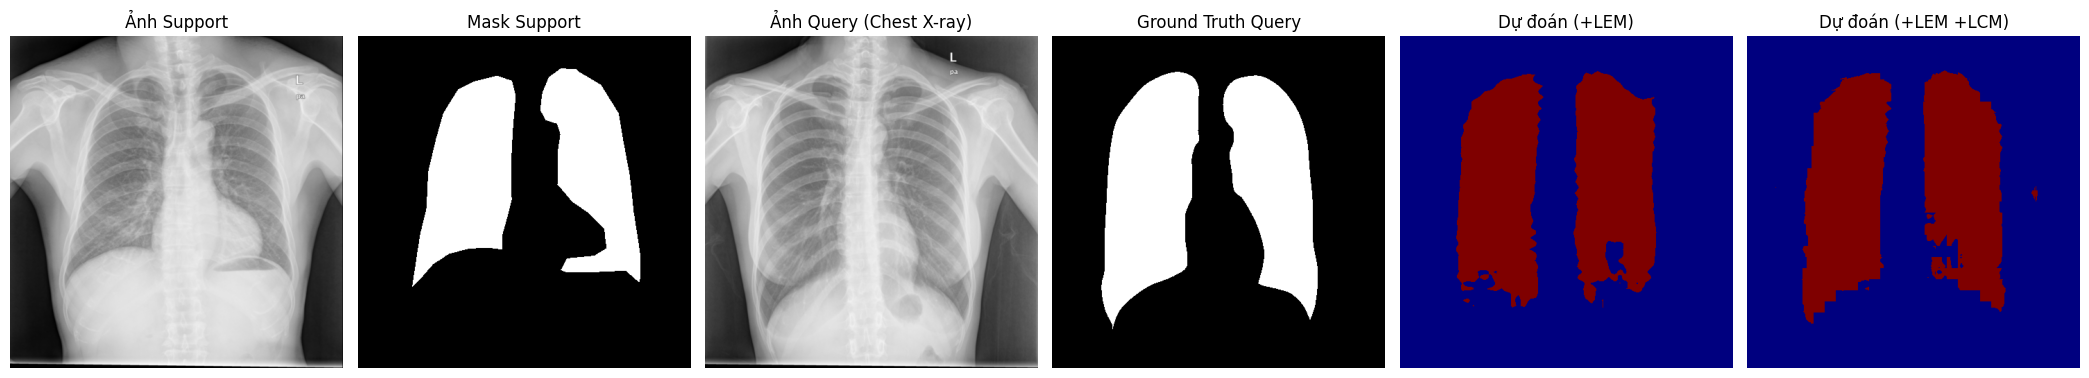


--- TRỰC QUAN HÓA MIỀN ĐÍCH: FSS-1000 ---


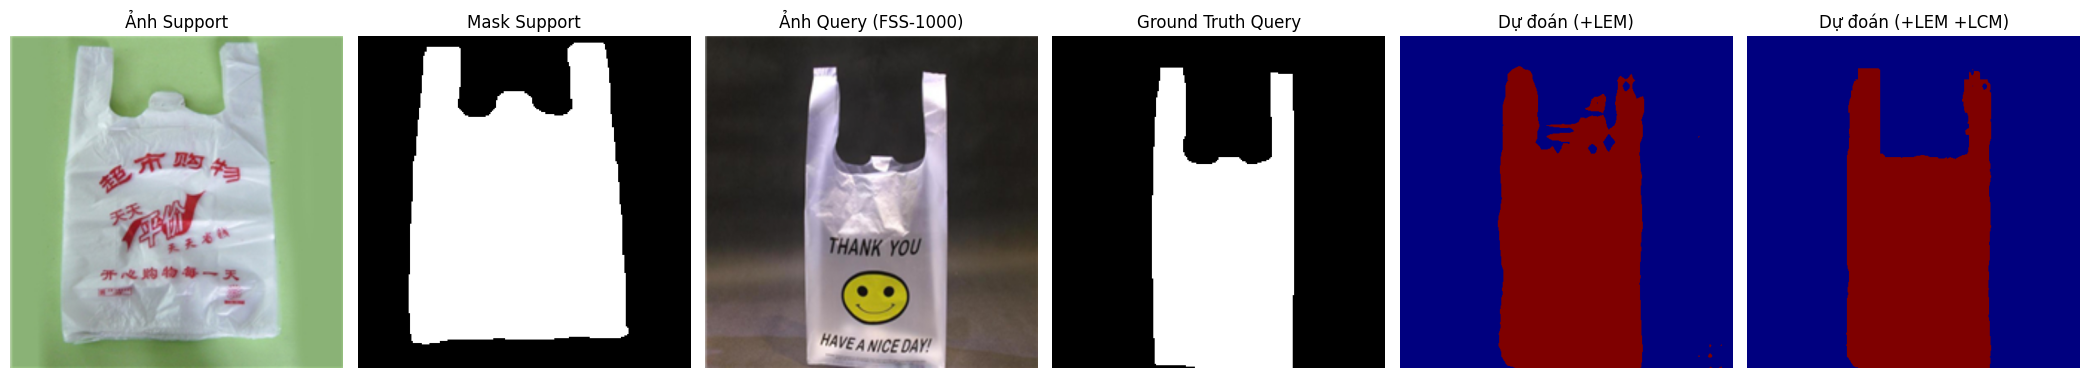


--- TRỰC QUAN HÓA MIỀN ĐÍCH: ISIC-2018 ---


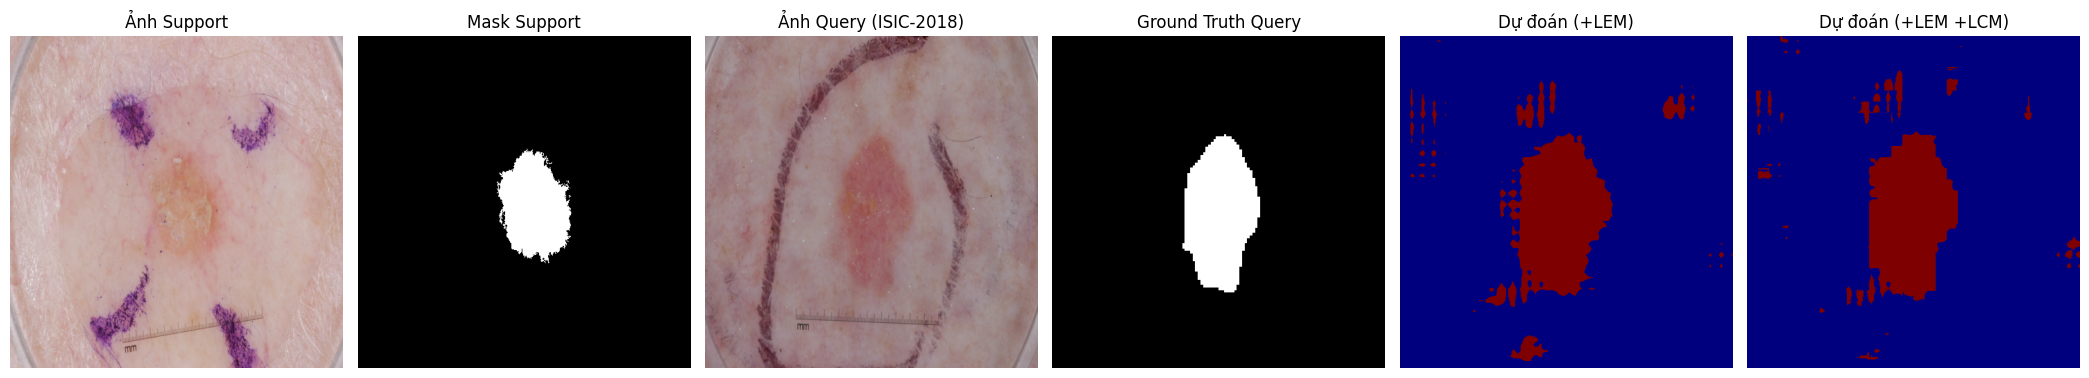


--- TRỰC QUAN HÓA MIỀN ĐÍCH: DeepGlobe ---


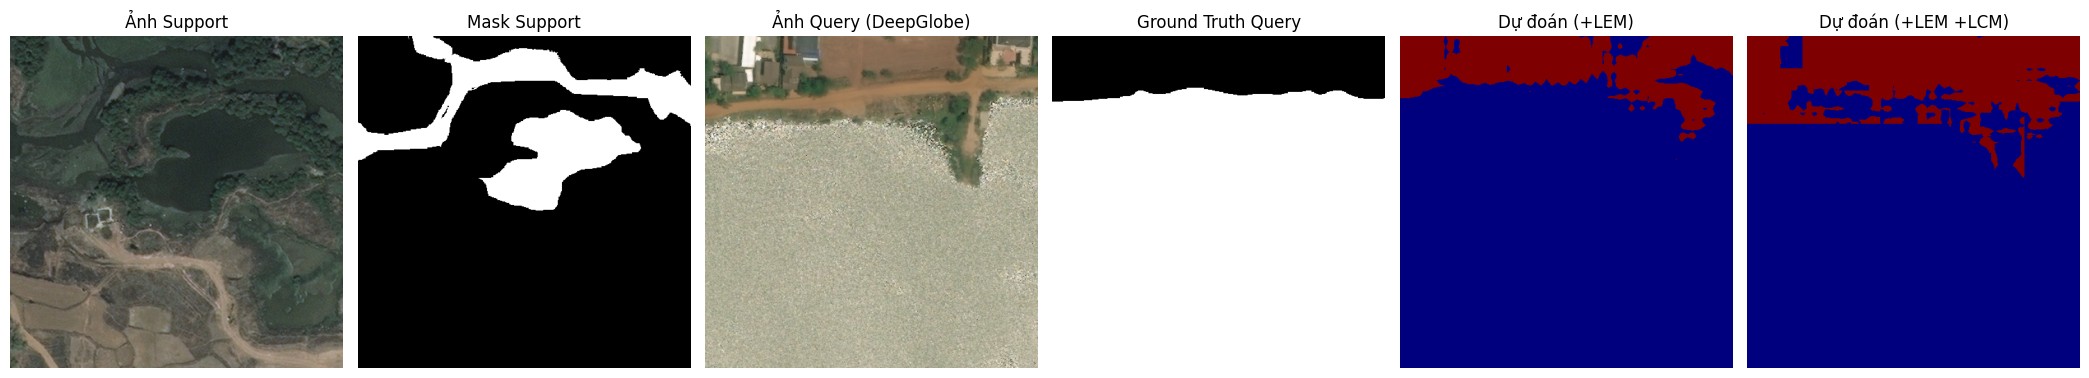

In [7]:
def visualize_predictions(model, domain_name='Chest X-ray', episode_idx=0):
    model.eval()
    data_list = scan_benchmark_directory(domain_name)
    test_ds = RealEpisodicDataset(data_list, n_shot=1, episodes=episode_idx + 1, is_train=False)
    sample = test_ds[episode_idx]

    img_s = sample['img_s'].unsqueeze(0).to(device)
    mask_s = sample['mask_s'].unsqueeze(0).to(device)
    img_q = sample['img_q'].unsqueeze(0).to(device)
    mask_q = sample['mask_q'].unsqueeze(0).to(device)
    q_ori = sample['q_ori'].unsqueeze(0).to(device)

    img_s_list = [img_s[:, k] for k in range(img_s.shape[1])]
    mask_s_list = [mask_s[:, k] for k in range(mask_s.shape[1])]

    with torch.no_grad():
        pred_no_lcm = torch.argmax(model(img_s_list, mask_s_list, img_q, use_mask_correction=False, use_lem=False), dim=1)
        pred_with_lcm = torch.argmax(model(img_s_list, mask_s_list, img_q, use_mask_correction=True, mask_k=0.6, mask_b=0.7, q_ori=q_ori, use_lem=False), dim=1)

    def denorm(t):
        t = t.clone().cpu().squeeze(0)
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        t = t * std + mean
        return torch.clamp(t, 0, 1).permute(1, 2, 0).numpy()

    fig, axes = plt.subplots(1, 6, figsize=(21, 3.8))
    axes[0].imshow(denorm(img_s[:, 0]))
    axes[0].set_title("Ảnh Support")
    axes[1].imshow(mask_s.cpu().squeeze(), cmap='gray')
    axes[1].set_title("Mask Support")
    axes[2].imshow(denorm(img_q))
    axes[2].set_title(f"Ảnh Query ({domain_name})")
    axes[3].imshow((mask_q.cpu().squeeze() == 1).numpy(), cmap='gray')
    axes[3].set_title("Ground Truth Query")
    axes[4].imshow(pred_no_lcm.cpu().squeeze(), cmap='jet')
    axes[4].set_title("Dự đoán (+LEM)")
    axes[5].imshow(pred_with_lcm.cpu().squeeze(), cmap='jet')
    axes[5].set_title("Dự đoán (+LEM +LCM)")

    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

for dom in ['Chest X-ray', 'FSS-1000', 'ISIC-2018', 'DeepGlobe']:
    print(f"\n--- TRỰC QUAN HÓA MIỀN ĐÍCH: {dom} ---")
    visualize_predictions(trained_loec_model, dom)
